In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import files

In [2]:
os.makedirs('images', exist_ok=True)

print("Please Upload The Required Images:")
print("- blox.jpg")
print("- box.png")
print("- box_in_scene.png")

uploaded = files.upload()

for filename in uploaded.keys():
   dest = os.path.join('images', filename)
   os.rename(filename, dest)
   print(f"File '{filename}' Moved To '{dest}'.")

print("\nContents Of Images Folder:")
print(os.listdir('images'))

Please Upload The Required Images:
- blox.jpg
- box.png
- box_in_scene.png


Saving blox.jpg to blox.jpg
Saving box.png to box.png
Saving box_in_scene.png to box_in_scene.png
File 'blox.jpg' Moved To 'images/blox.jpg'.
File 'box.png' Moved To 'images/box.png'.
File 'box_in_scene.png' Moved To 'images/box_in_scene.png'.

Contents Of Images Folder:
['box_in_scene.png', 'blox.jpg', 'box.png']


In [3]:
cv2.__version__

'4.14.0'

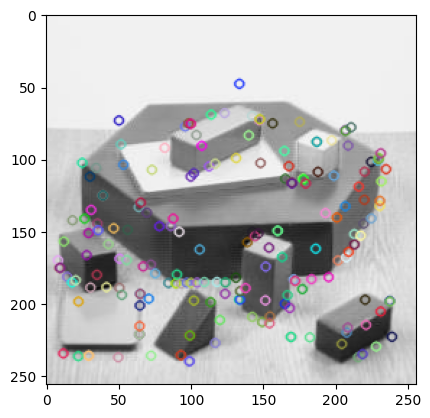

In [4]:
img = cv2.imread('images/blox.jpg')

img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

sift = cv2.SIFT_create()
kp = sift.detect(img_gray, None)
img_sift = cv2.drawKeypoints(img, kp, img)

plt.imshow(img)

plt.show()

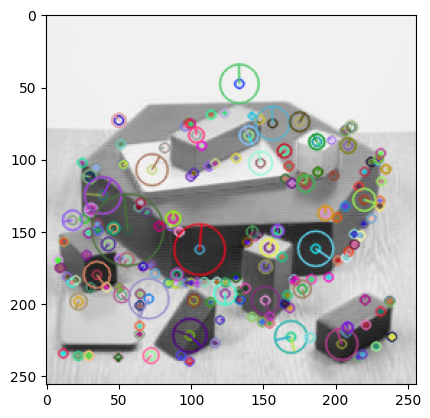

In [10]:
r = cv2.drawKeypoints(img, kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

plt.imshow(r)

plt.show()

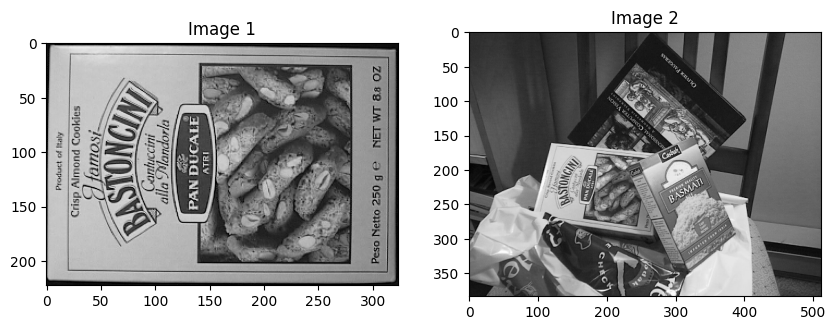

In [6]:
img1 = cv2.imread('images/box.png')
img2 = cv2.imread('images/box_in_scene.png')

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img1[..., ::-1])
plt.title('Image 1')

plt.subplot(1, 2, 2)
plt.imshow(img2[..., ::-1])
plt.title('Image 2')

plt.show()

In [7]:
sift = cv2.SIFT_create()

kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

print(des1.shape)
print(des2.shape)

(604, 128)
(969, 128)


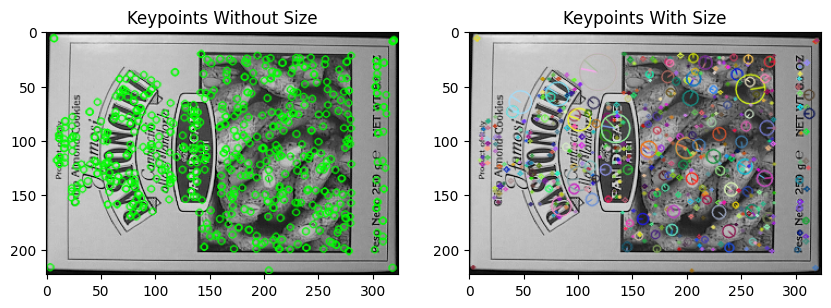

In [8]:
keypoint_without_size = np.copy(img1)
keypoint_with_size = np.copy(img1)

cv2.drawKeypoints(img1, kp1, keypoint_without_size, color=(0, 255, 0))
cv2.drawKeypoints(img1, kp1, keypoint_with_size, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(keypoint_without_size[..., ::-1])
plt.title('Keypoints Without Size')

plt.subplot(1, 2, 2)
plt.imshow(keypoint_with_size[..., ::-1])
plt.title('Keypoints With Size')

plt.show()

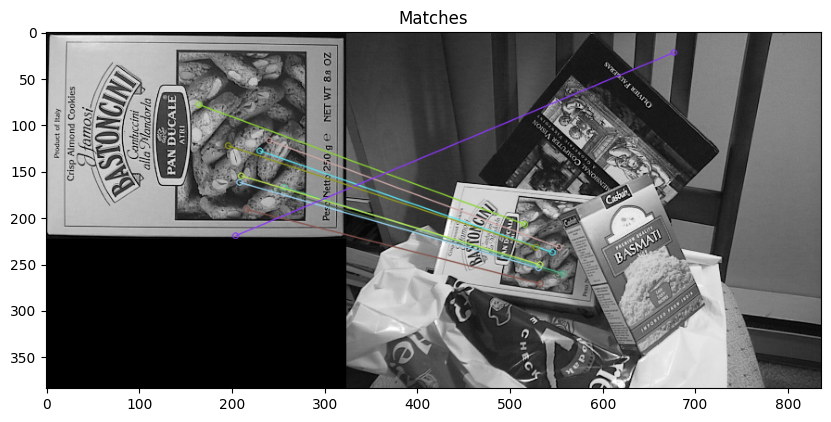

In [9]:
bf = cv2.BFMatcher(cv2.NORM_L1, crossCheck=False)

matches = bf.match(des1, des2)
matches = sorted(matches, key=lambda x: x.distance)

img3 = cv2.drawMatches(img1, kp1, img2, kp2, matches[:10], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize=(10, 5))

plt.imshow(img3[..., ::-1])
plt.title('Matches')

plt.show()